In [1]:
import hashlib
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import torch

from hydra import compose, initialize_config_dir

cwd = Path.cwd().resolve()
REPO_ROOT = next(
    p for p in (cwd, *cwd.parents)
    if (p / "maps_to_cosmology").is_dir()
)

PACKAGE_DIR = REPO_ROOT / "maps_to_cosmology"
NOTEBOOK_DIR = PACKAGE_DIR / "notebooks"
RUN_DIR = (
    PACKAGE_DIR
    / "results_cosmogrid_64x64_native"
    / "train_mean_true_sigma_1.0"
)

COSMOGRID_DIR = Path(
    "/data/scratch/convergence_maps/cosmogrid_native_healpix_64x64"
)

DC2_ARCHIVE = (
    NOTEBOOK_DIR
    / "dc2_native_healpix.npz"
)

if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from maps_to_cosmology.flowmatching import FlowMatching

EVAL_SEED = 42

np.random.seed(EVAL_SEED)
torch.manual_seed(EVAL_SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(EVAL_SEED)

device = torch.device("cuda:7" if torch.cuda.is_available() else "cpu")

Initialize the config:

In [2]:
with initialize_config_dir(
    config_dir=str(PACKAGE_DIR / "configs"),
    version_base=None,
):
    cfg = compose(
        config_name="train_flowmatching_cosmogrid_dc2_native",
        overrides=[
            "seed=42",
            "convergence_maps.split_seed=42",
            f"paths.cosmogrid_data_dir={COSMOGRID_DIR}",
            "convergence_maps.subtract_train_region_mean=true",
            "convergence_maps.smoothing_sigma=1.0",
            "convergence_maps.augment=false",
        ],
    )

Instantiate the encoder using the checkpoint from a previous training run:

In [3]:
ckpts = sorted(
    (RUN_DIR / "checkpoints").glob("*.ckpt")
)

ckpt_path = ckpts[0]

ckpt_metadata = torch.load(
    ckpt_path,
    map_location="cpu",
    weights_only=False,
)

ckpt_num_bins = int(
    ckpt_metadata["hyper_parameters"]["num_bins"]
)

print("Checkpoint:", ckpt_path)
print("Checkpoint num_bins:", ckpt_num_bins)

Checkpoint: /home/pdailin/blissWL/maps_to_cosmology/results_cosmogrid_64x64_native/train_mean_true_sigma_1.0/checkpoints/flowmatching_epoch=184.ckpt
Checkpoint num_bins: 4


Instantiate the test dataloader:

In [4]:
from maps_to_cosmology.datamodule_cosmogrid_native import (
    NativeCosmoGridMapsModule,
)

dm_kwargs = dict(ckpt_metadata["datamodule_hyper_parameters"])
dm_kwargs.update(
    data_dir=str(COSMOGRID_DIR),
    num_workers=0,
)

datamodule = NativeCosmoGridMapsModule(**dm_kwargs)
datamodule.load_state_dict(
    ckpt_metadata["NativeCosmoGridMapsModule"]
)
datamodule.setup("test")

test_loader = datamodule.test_dataloader()

In [5]:
train_mean = datamodule.param_mean.cpu()
train_std = datamodule.param_std.cpu()

print("train_mean:", train_mean)
print("train_std:", train_std)

train_mean: tensor([ 0.2466,  0.0450,  0.8275,  0.7154,  0.9681, -0.9453])
train_std: tensor([0.0934, 0.0066, 0.2312, 0.0449, 0.0440, 0.2766])


Load in the convergence maps from the test set and evaluate the model on them. Also load the correspoding cosmological parameters from the test set:

In [6]:
num_samples_per_model = 1000

member_samples = []
true_params = None

mean = train_mean.view(1, 1, -1)
std = train_std.view(1, 1, -1)

for model_idx, ckpt in enumerate(ckpts):
    model_seed = EVAL_SEED + model_idx

    torch.manual_seed(model_seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(model_seed)

    print(f"Loading {ckpt}")

    model = FlowMatching.load_from_checkpoint(
        ckpt,
        weights_only=False,
        map_location=device,
    )
    model.eval()
    model.to(device)

    model_samples = []
    current_true_params = []

    with torch.inference_mode():
        for maps, params_std in test_loader:
            batch_size = maps.shape[0]
            maps = maps.to(device)

            assert maps.shape[1:] == (4, 64, 64)

            x_embedding = model.map_encoder(maps)
            x_expanded = x_embedding.repeat(
                num_samples_per_model,
                1,
            )

            batch_samples_std = model._integrate_ode(
                x_expanded
            )

            batch_samples_std = batch_samples_std.view(
                num_samples_per_model,
                batch_size,
                -1,
            ).cpu()

            batch_samples = (
                batch_samples_std * std + mean
            )

            params_physical = (
                params_std.cpu()
                * train_std.view(1, -1)
                + train_mean.view(1, -1)
            )

            model_samples.append(batch_samples)
            current_true_params.append(params_physical)

    model_samples = torch.cat(
        model_samples,
        dim=1,
    )

    member_samples.append(model_samples)

    if true_params is None:
        true_params = torch.cat(
            current_true_params,
            dim=0,
        )

all_samples = torch.cat(
    member_samples,
    dim=0,
)

posterior_means = all_samples.mean(dim=0)
posterior_stdevs = all_samples.std(
    dim=0,
    unbiased=False,
)

expected_num_samples = (
    len(ckpts) * num_samples_per_model
)

n_test = len(datamodule.test_dataset)

print("all_samples:", all_samples.shape)
print("true_params:", true_params.shape)

Loading /home/pdailin/blissWL/maps_to_cosmology/results_cosmogrid_64x64_native/train_mean_true_sigma_1.0/checkpoints/flowmatching_epoch=184.ckpt


all_samples: torch.Size([1000, 4848, 6])
true_params: torch.Size([4848, 6])


For each of the six cosmological parameters, create a scatterplot of the true parameter value versus the posterior mean. Arrange the six scatterplots in a 2x3 grid.

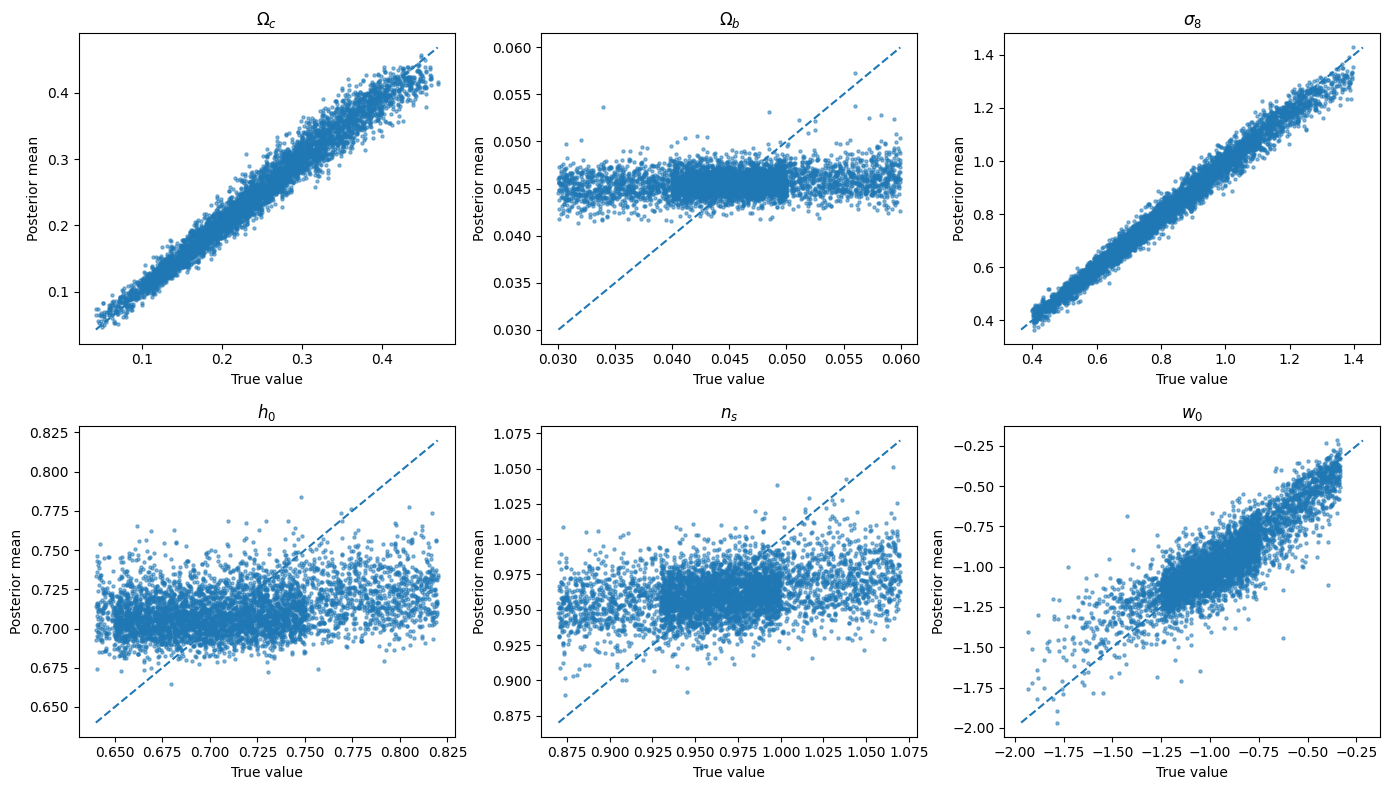

In [7]:
param_names = [
    r"$\Omega_c$", r"$\Omega_b$", r"$\sigma_8$",
    r"$h_0$", r"$n_s$", r"$w_0$"
]

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()

for i in range(6):
    ax = axes[i]

    x = true_params[:, i].numpy()
    y = posterior_means[:, i].numpy()

    ax.scatter(x, y, s=5, alpha=0.5)
    minv = min(x.min(), y.min())
    maxv = max(x.max(), y.max())
    ax.plot([minv, maxv], [minv, maxv], linestyle="--")

    ax.set_xlabel("True value")
    ax.set_ylabel("Posterior mean")
    ax.set_title(param_names[i])

plt.tight_layout()
plt.show()

We load in the real DC2 map used as a reference map:

In [8]:
reference_map = np.load("dc2_native_healpix.npy")[..., :4]
reference_params = torch.tensor(
    [0.22, 0.0448, 0.80, 0.71, 0.963, -1.0]
)

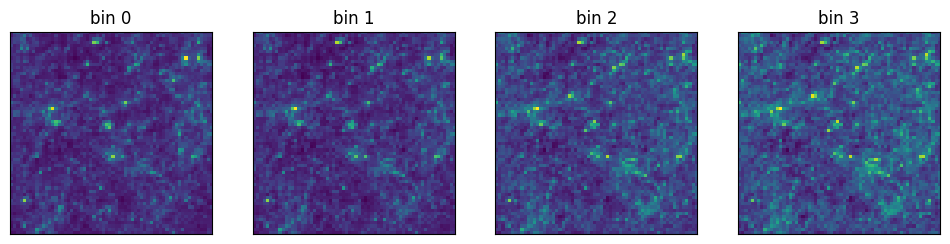

In [9]:
fig, ax = plt.subplots(1, 4, figsize = (12, 3))

for b in range(4):
    _ = ax[b].imshow(reference_map[...,b])
    _ = ax[b].set_title(f"bin {b}")
    _ = ax[b].set_xticks([])
    _ = ax[b].set_yticks([])

We plug this reference map into our trained model and plot the contours of the resulting posterior distributions:

In [10]:
from torchvision.transforms.functional import gaussian_blur

reference_map = np.load(
    "dc2_native_healpix.npy"
)

reference_map_tensor = (
    torch.from_numpy(reference_map)
    .permute(2, 0, 1)
    .unsqueeze(0)
    .float()
)

# Apply exactly the same smoothing used during training.
sigma = cfg.convergence_maps.get(
    "smoothing_sigma",
    None,
)

if sigma is not None:
    sigma = float(sigma)
    kernel_size = 2 * round(2 * sigma) + 1

    reference_map_tensor = gaussian_blur(
        reference_map_tensor,
        kernel_size=[kernel_size, kernel_size],
        sigma=[sigma, sigma],
    )

reference_map_tensor = reference_map_tensor.to(device)

num_samples_per_model = 1000
reference_ensemble_samples = []

for ckpt in ckpts:
    model = FlowMatching.load_from_checkpoint(
        ckpt,
        weights_only=False,
        map_location=device,
    )
    model.eval()
    model.to(device)

    with torch.inference_mode():
        x_embedding = model.map_encoder(
            reference_map_tensor
        )

        x_expanded = x_embedding.repeat(
            num_samples_per_model,
            1,
        )

        samples_std = model._integrate_ode(
            x_expanded
        )

    # Convert to physical parameter space.
    samples = (
        samples_std.cpu()
        * train_std.unsqueeze(0)
        + train_mean.unsqueeze(0)
    )

    reference_ensemble_samples.append(samples)

reference_map_samples = torch.cat(
    reference_ensemble_samples,
    dim=0,
)

print(reference_map_samples.shape)

torch.Size([1000, 6])


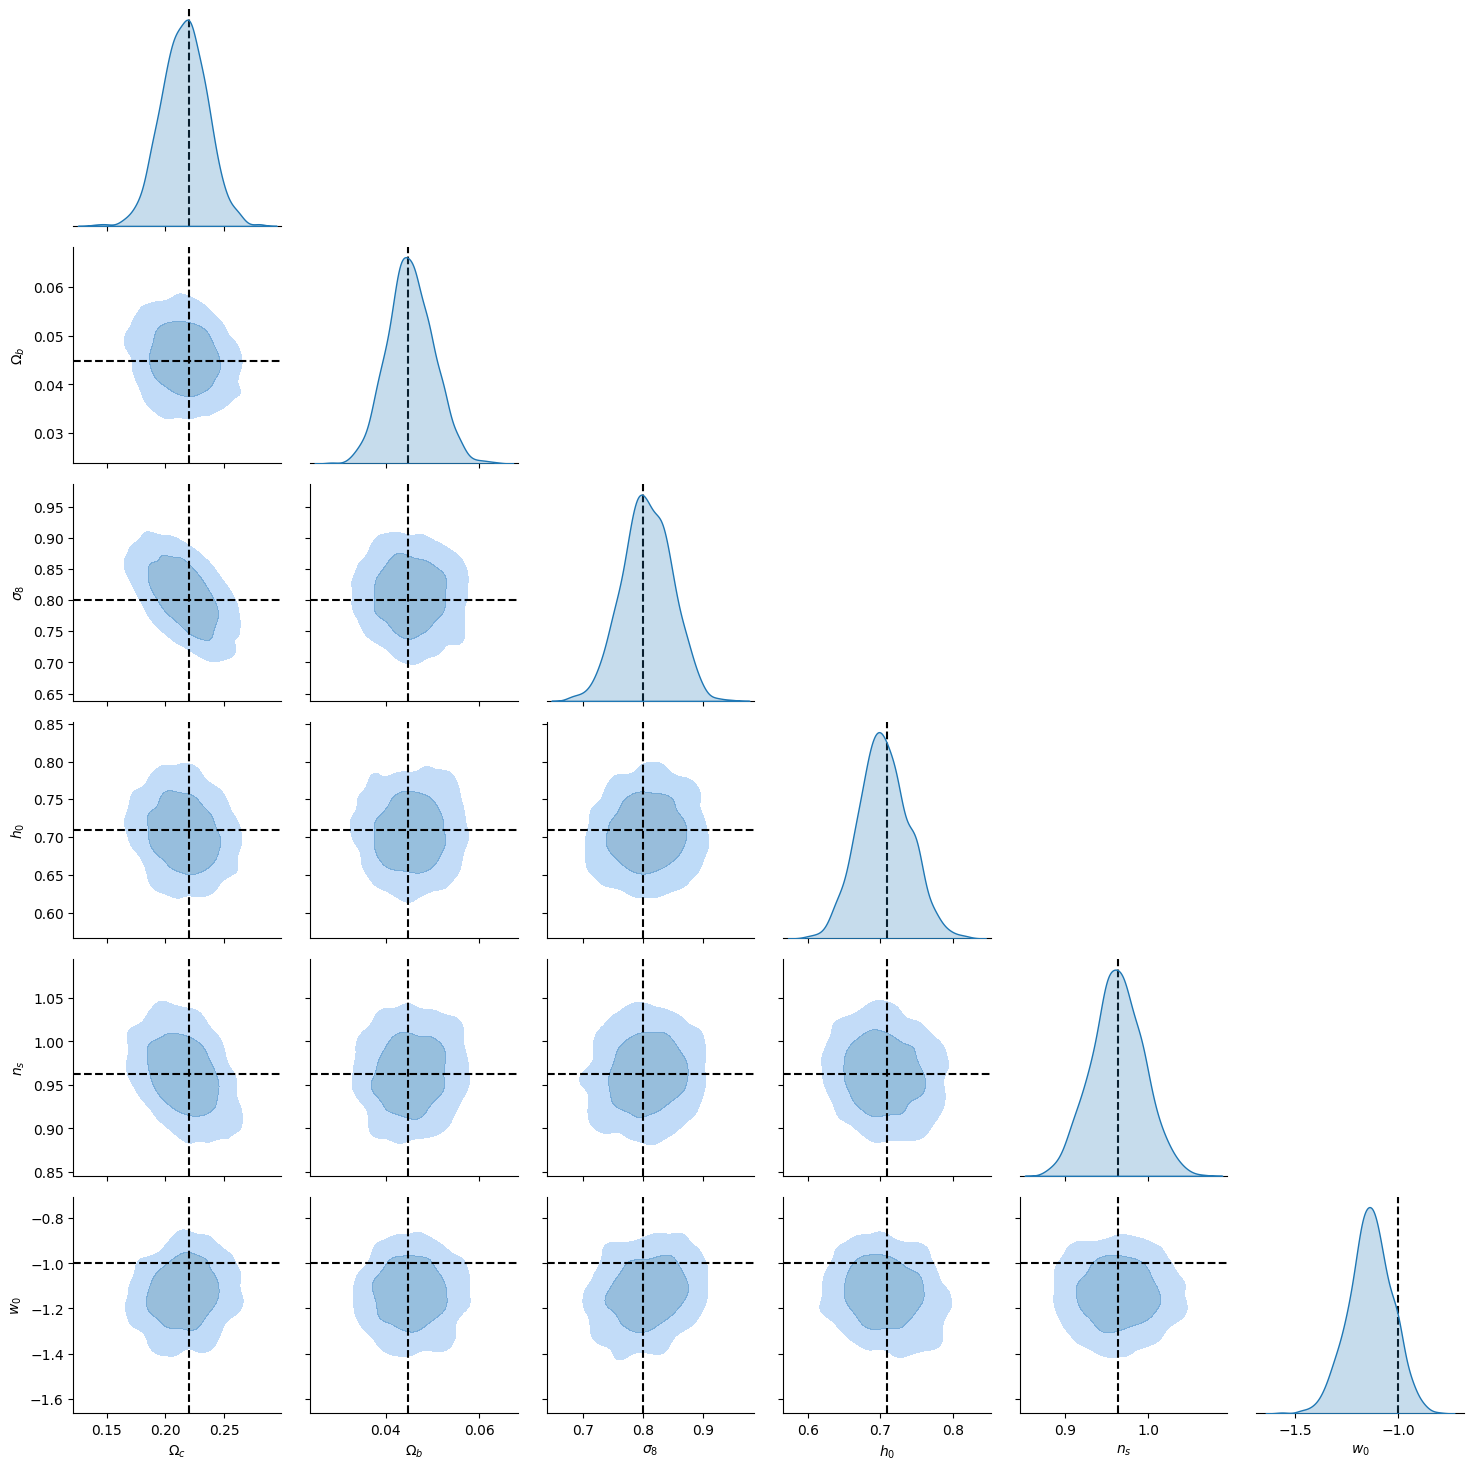

In [11]:
df = pd.DataFrame(
    reference_map_samples.numpy(),
    columns=param_names,
)

true_vals = reference_params.numpy()

g = sns.PairGrid(df, corner=True, diag_sharey=False)
g.map_diag(sns.kdeplot, fill=True)
g.map_lower(sns.kdeplot, levels=[0.05, 0.32, 1.0], fill=True, alpha=0.5)

for i in range(6):
    g.axes[i, i].axvline(
        true_vals[i],
        color="black",
        linestyle="--",
    )

    for j in range(i):
        g.axes[i, j].axvline(
            true_vals[j],
            color="black",
            linestyle="--",
        )
        g.axes[i, j].axhline(
            true_vals[i],
            color="black",
            linestyle="--",
        )

Include light grey dots to show the prior space, i.e. the cosmology parameter set corresponding to the training data:

In [12]:
train_params_physical = torch.unique(
    torch.stack([
        record.parameters
        for record in datamodule.train_dataset.records
    ]),
    dim=0,
)

training_param_df = pd.DataFrame(
    train_params_physical.numpy(),
    columns=param_names,
)

print(
    "Unique CosmoGrid training cosmologies:",
    len(training_param_df),
)

Unique CosmoGrid training cosmologies: 2424


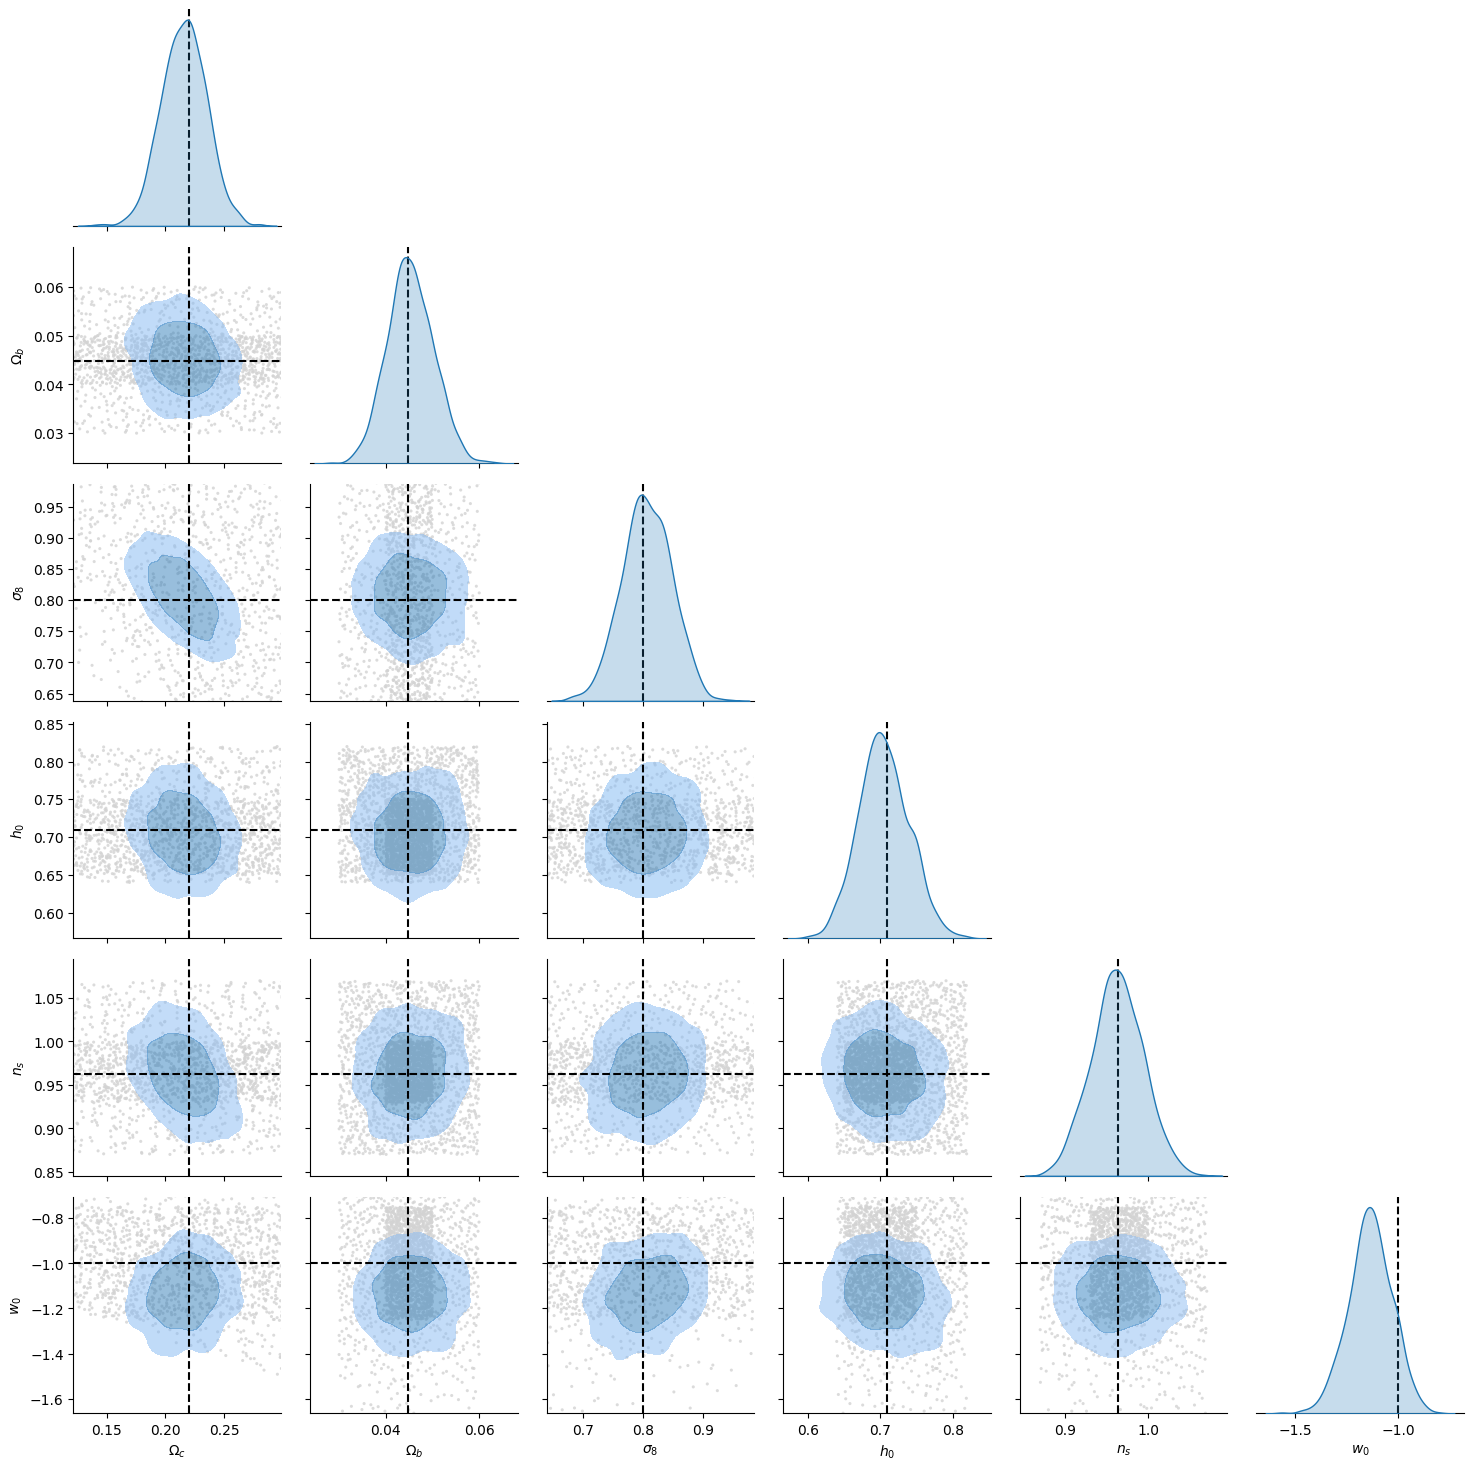

In [13]:
from matplotlib.lines import Line2D

posterior_df = pd.DataFrame(
    reference_map_samples.numpy(),
    columns=param_names,
)

true_vals = reference_params.numpy()

g = sns.PairGrid(
    posterior_df,
    corner=True,
    diag_sharey=False,
)

# Posterior marginals and contours.
g.map_diag(
    sns.kdeplot,
    fill=True,
)

g.map_lower(
    sns.kdeplot,
    levels=[0.05, 0.32, 1.0],
    fill=True,
    alpha=0.5,
)

# DC2 truth.
for row in range(len(param_names)):
    g.axes[row, row].axvline(
        true_vals[row],
        color="black",
        linestyle="--",
    )

    for col in range(row):
        ax = g.axes[row, col]

        ax.axvline(
            true_vals[col],
            color="black",
            linestyle="--",
        )

        ax.axhline(
            true_vals[row],
            color="black",
            linestyle="--",
        )

# Save each subplot's original axis limits.
original_limits = {}

for row in range(len(param_names)):
    for col in range(row + 1):
        ax = g.axes[row, col]
        original_limits[(row, col)] = (
            ax.get_xlim(),
            ax.get_ylim(),
        )

# Add prior scatter points to the lower-triangle subplots.
for row in range(1, len(param_names)):
    for col in range(row):
        g.axes[row, col].scatter(
            training_param_df.iloc[:, col],
            training_param_df.iloc[:, row],
            s=5,
            color="lightgrey",
            alpha=0.8,
            edgecolors="none",
            rasterized=True,
            zorder=0,
        )

# Restore the original axis limits.
for (row, col), (xlim, ylim) in original_limits.items():
    ax = g.axes[row, col]
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

# g.figure.savefig("figures_paper/contourplot_cosmogrid_native_dc2.png", dpi=600, transparent=True, bbox_inches="tight", pad_inches=0)

# plt.show()

We plug a map from test set into our trained model and plot the contours of the resulting posterior distributions:

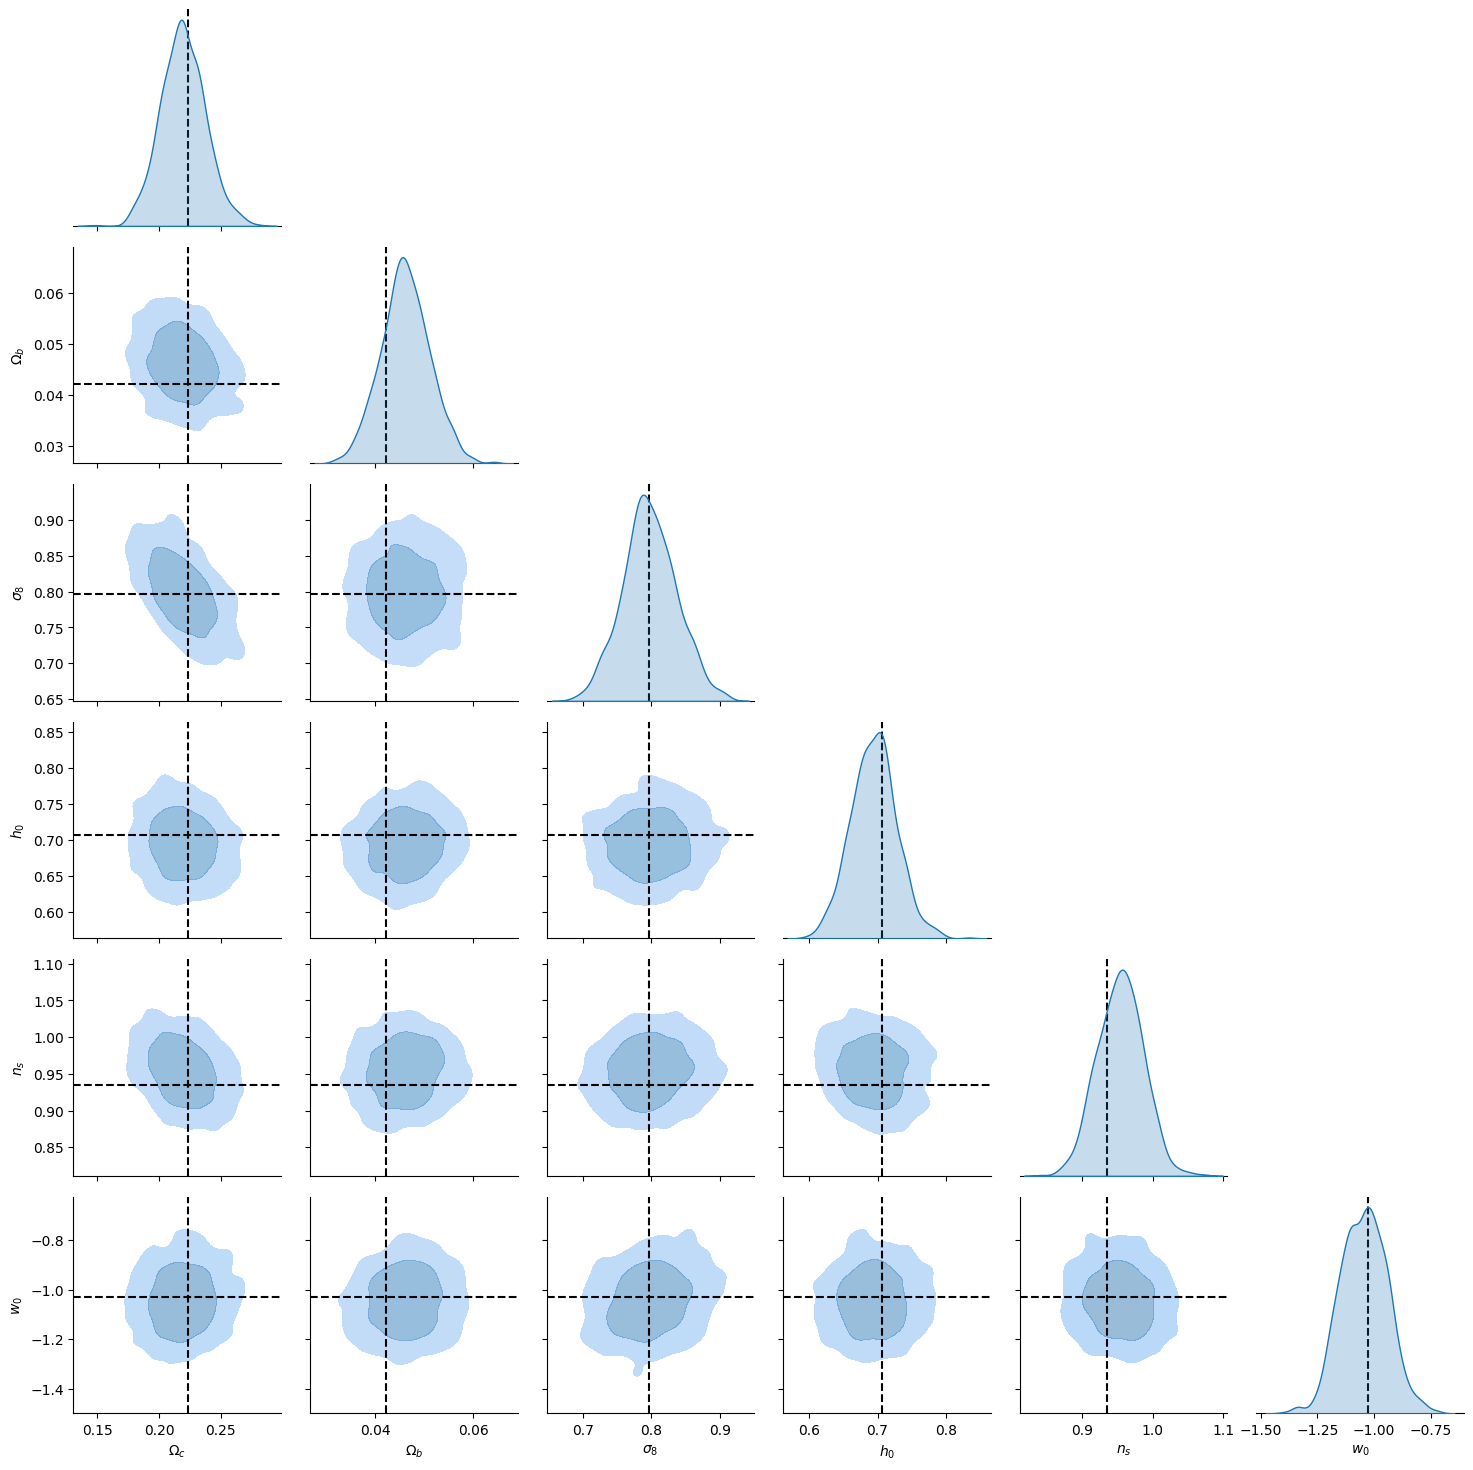

In [14]:
sample_idx = 3342
selected_params = true_params[sample_idx]

samples = all_samples[:, sample_idx, :]  # (3000, 6)

posterior_mean = samples.mean(dim=0)
posterior_stdev = samples.std(dim=0)
df = pd.DataFrame(samples.numpy(), columns=param_names)

g = sns.PairGrid(df, corner=True, diag_sharey=False)
g.map_diag(sns.kdeplot, fill=True)
g.map_lower(sns.kdeplot, levels=[0.05, 0.32, 1.0], fill=True, alpha=0.5)

true_vals = selected_params.cpu().numpy()

for i in range(6):
    g.axes[i, i].axvline(true_vals[i], color="black", linestyle="--")
    for j in range(i):
        g.axes[i, j].axvline(true_vals[j], color="black", linestyle="--")
        g.axes[i, j].axhline(true_vals[i], color="black", linestyle="--")

# g.figure.savefig("figures_paper/contourplot_cosmogrid_native_heldout.png", dpi=600, transparent=True, bbox_inches="tight", pad_inches=0)

# plt.show()

Plot credible intervals:

Credible Interval Level: 90%
$\Omega_c$: Coverage = 0.950
$\Omega_b$: Coverage = 0.880
$\sigma_8$: Coverage = 0.962
$h_0$: Coverage = 0.922
$n_s$: Coverage = 0.870
$w_0$: Coverage = 0.884


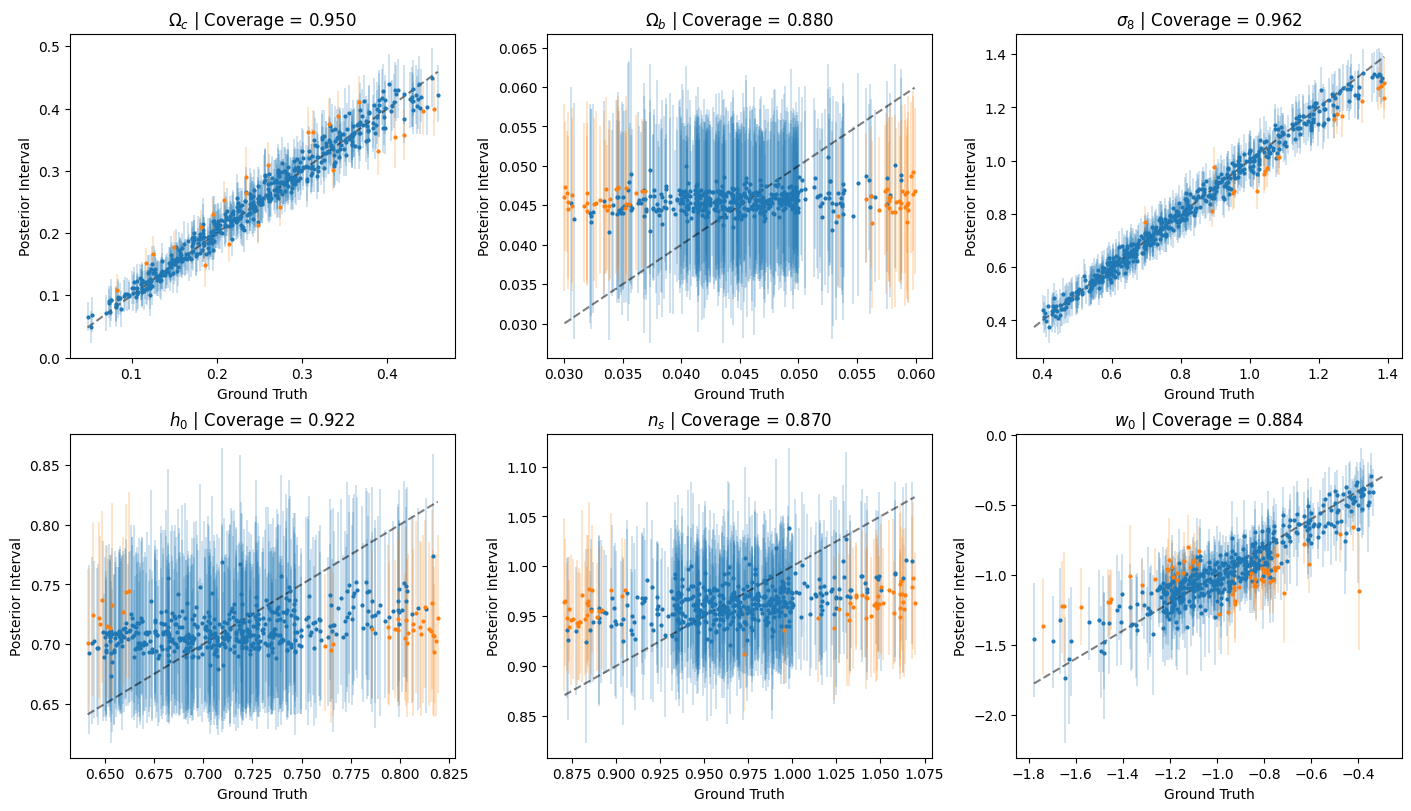

In [15]:
ci_level = 0.90
alpha = 1 - ci_level
lower_q = alpha / 2
upper_q = 1 - alpha / 2

n_plot = 500
rng = np.random.default_rng(42)

mu = all_samples.mean(dim=0).numpy()
lower = torch.quantile(all_samples, lower_q, dim=0).numpy()
upper = torch.quantile(all_samples, upper_q, dim=0).numpy()
true = true_params.numpy()

N = true.shape[0]
idx = rng.choice(N, size=min(n_plot, N), replace=False)

fig, axes = plt.subplots(2, 3, figsize=(14, 8), constrained_layout=True)
axes = axes.ravel()

print(f"Credible Interval Level: {int(ci_level * 100)}%")
coverages = []

for j, name in enumerate(param_names):
    x = true[idx, j]
    y = mu[idx, j]
    lo = lower[idx, j]
    hi = upper[idx, j]

    covered = (x >= lo) & (x <= hi)
    cov = covered.mean()
    coverages.append(cov)
    print(f"{name}: Coverage = {cov:.3f}")

    ax = axes[j]
    ax.errorbar(
        x[covered],
        y[covered],
        yerr=np.vstack([y[covered] - lo[covered], hi[covered] - y[covered]]),
        fmt="o",
        markersize=2,
        alpha=1,
        linewidth=0.3,
        capsize=0,
    )
    ax.errorbar(
        x[~covered],
        y[~covered],
        yerr=np.vstack([y[~covered] - lo[~covered], hi[~covered] - y[~covered]]),
        fmt="o",
        markersize=2,
        alpha=1,
        linewidth=0.3,
        capsize=0,
    )
    dmin = min(x.min(), y.min())
    dmax = max(x.max(), y.max())
    ax.plot([dmin, dmax], [dmin, dmax], "k--", alpha=0.5)
    ax.set_xlabel("Ground Truth")
    ax.set_ylabel("Posterior Interval")
    ax.set_title(f"{name} | Coverage = {cov:.3f}")
plt.show()

# fig.savefig("figures_paper/credibleintervals_cosmogrid_native.png", dpi=600, transparent=True, bbox_inches="tight", pad_inches=0)

Empirical Coverage vs Nominal Coverage

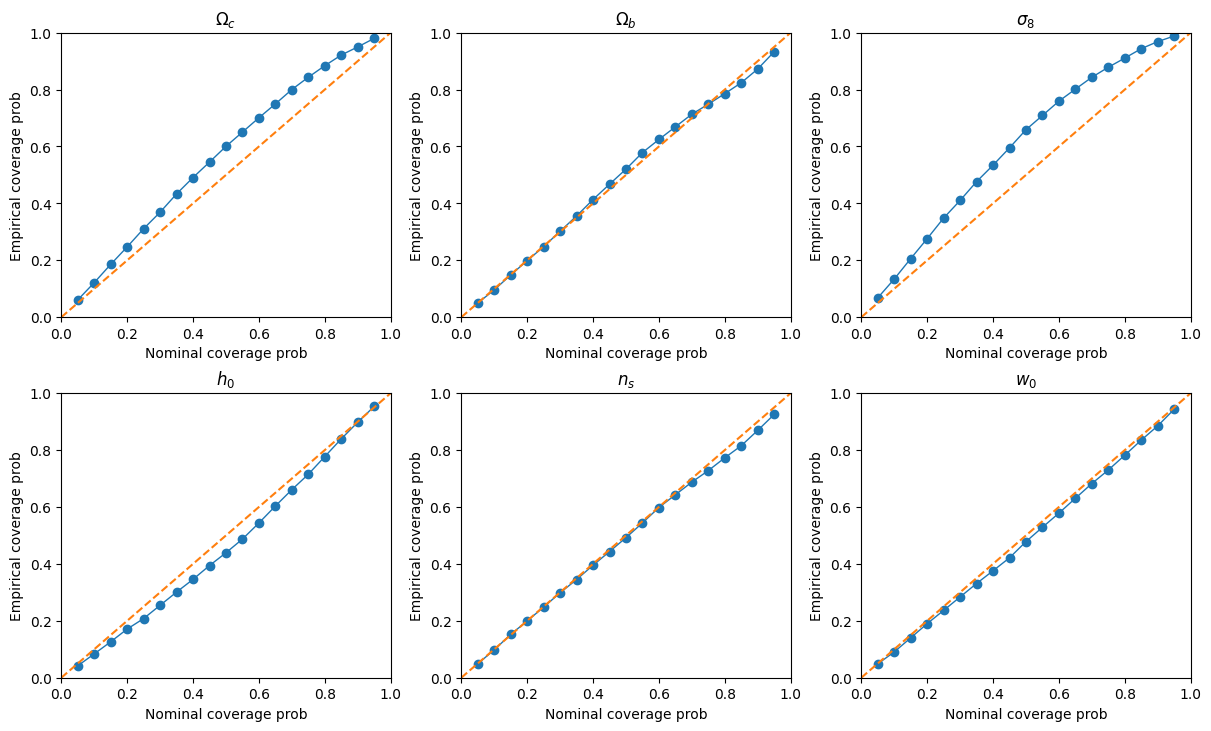

ECE per parameter:
  $\Omega_c$: 0.0708
  $\Omega_b$: 0.0126
  $\sigma_8$: 0.1058
  $h_0$: 0.0349
  $n_s$: 0.0106
  $w_0$: 0.0162


In [16]:
levels = np.linspace(0.05, 0.95, 19)                                                                                                                              
K = len(levels)                                                                                                                                                 
                                                                                                                                                                
y_true = true_params.numpy()                                                                                                                                      
                                                                                                                                                                
N, d = y_true.shape                                       
assert d == len(param_names)

lower_qs = torch.tensor([(1 - c) / 2 for c in levels], dtype=all_samples.dtype)                                                                                                            
upper_qs = torch.tensor([(1 + c) / 2 for c in levels], dtype=all_samples.dtype)
all_lower = torch.quantile(all_samples, lower_qs, dim=0).numpy()  # (K, N_test, 6)                                                                                
all_upper = torch.quantile(all_samples, upper_qs, dim=0).numpy()  # (K, N_test, 6)                                                                                
                                                                                                                                                                
emp = np.zeros((K, d), dtype=float)                                                                                                                               
for k in range(K):                                                                                                                                                
    inside = (y_true >= all_lower[k]) & (y_true <= all_upper[k])
    emp[k] = inside.mean(axis=0)

ncols = 3
nrows = int(np.ceil(d / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4*ncols, 3.6*nrows), constrained_layout=True)
axes = np.array(axes).reshape(-1)

for j in range(d):
    ax = axes[j]
    ax.plot(levels, emp[:, j], marker="o", linewidth=1)
    ax.plot([0, 1], [0, 1], linestyle="--")
    ax.set_title(param_names[j])
    ax.set_xlabel("Nominal coverage prob")
    ax.set_ylabel("Empirical coverage prob")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)

for j in range(d, len(axes)):
    axes[j].axis("off")

plt.show()
ece = np.mean(np.abs(emp - levels[:, None]), axis=0)
print("ECE per parameter:")
for name, val in zip(param_names, ece):
    print(f"  {name}: {val:.4f}")

# fig.savefig("figures_paper/calibration_cosmogrid_native.png", dpi=600, transparent=True, bbox_inches="tight", pad_inches=0)

### $S_8$–$\Omega_m$ posterior for one held-out CosmoGrid map
We use $\Omega_m=\Omega_c+\Omega_b$ and $S_8=\sigma_8\sqrt{\Omega_m/0.3}$.

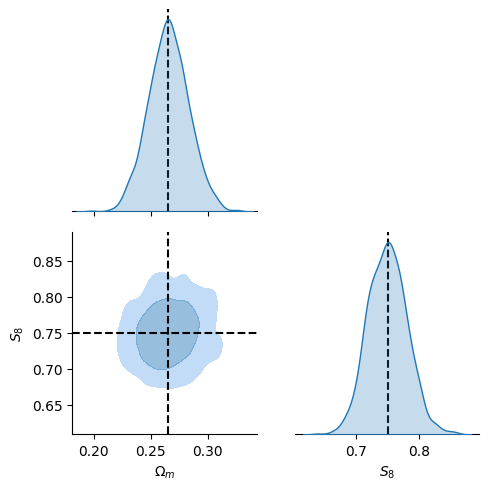

In [17]:
from matplotlib.lines import Line2D

def omega_m_s8(params):
    if isinstance(params, torch.Tensor):
        params = params.detach().cpu().numpy()

    omega_m = params[..., 0] + params[..., 1]   # omega_c + omega_b
    s8 = params[..., 2] * np.sqrt(np.clip(omega_m, 1e-8, None) / 0.3)

    return omega_m, s8


sample_idx = 3342  # choose one held-out CosmoGrid map from the test set

posterior = all_samples[:, sample_idx, :]       # ensemble mixture posterior
truth = true_params[sample_idx]

omega_m_samples, s8_samples = omega_m_s8(posterior)
omega_m_true, s8_true = omega_m_s8(truth[None, :])
omega_m_true = omega_m_true.item()
s8_true = s8_true.item()

df_s8 = pd.DataFrame({
    r"$\Omega_m$": omega_m_samples,
    r"$S_8$": s8_samples,
})

g = sns.PairGrid(df_s8, corner=True, diag_sharey=False)
g.map_diag(sns.kdeplot, fill=True)
g.map_lower(
    sns.kdeplot,
    levels=[0.05, 0.32, 1.0],
    fill=True,
    alpha=0.5,
)

ax_om = g.axes[0, 0]
ax_joint = g.axes[1, 0]
ax_s8 = g.axes[1, 1]

ax_om.axvline(omega_m_true, color="black", linestyle="--")
ax_joint.axvline(omega_m_true, color="black", linestyle="--")
ax_joint.axhline(s8_true, color="black", linestyle="--")
ax_s8.axvline(s8_true, color="black", linestyle="--")

# g.figure.savefig("figures_paper/S8_vs_OmM_cosmogrid_native_heldout.png", dpi=600, transparent=True, bbox_inches="tight", pad_inches=0)

# plt.show()

### $S_8$–$\Omega_m$ posterior for the DC2 reference map

`reference_map_samples` and `reference_params` are in physical (de-standardized) parameter space.

Because this baseline was trained only on CosmoGrid maps, this is an out-of-distribution diagnostic rather than a calibrated DC2 posterior.

Posterior samples: 1000
DC2 truth: Omega_m=0.2648, S_8=0.7516


(0.6169053147170566, 0.8673078586723783)

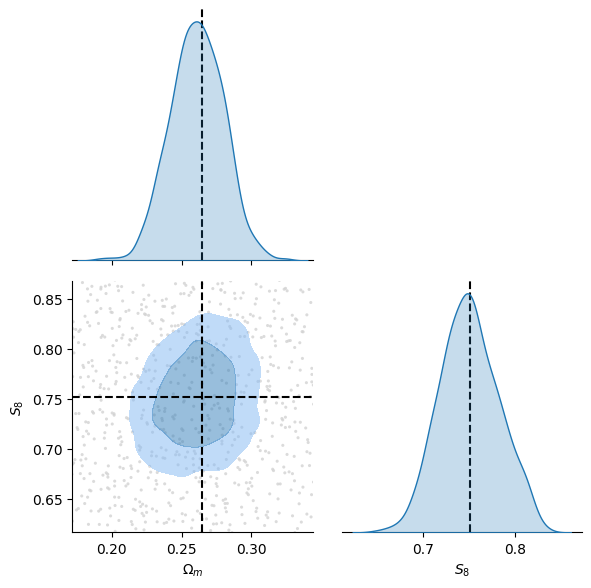

In [18]:
def omega_m_s8(params):
    if isinstance(params, torch.Tensor):
        params = params.detach().cpu().numpy()

    omega_m = params[..., 0] + params[..., 1]  # omega_c + omega_b
    s8 = params[..., 2] * np.sqrt(np.clip(omega_m, 1e-8, None) / 0.3)

    return omega_m, s8


# Physical-space posterior samples produced by the real-DC2 inference cell.
posterior = reference_map_samples.detach().cpu()

omega_m_samples, s8_samples = omega_m_s8(posterior)

reference_params_tensor = reference_params.detach().cpu().to(dtype=posterior.dtype)

omega_m_true, s8_true = omega_m_s8(reference_params_tensor[None, :])
omega_m_true = omega_m_true.item()
s8_true = s8_true.item()

df_s8_dc2 = pd.DataFrame({
    r"$\Omega_m$": omega_m_samples,
    r"$S_8$": s8_samples,
})

g = sns.PairGrid(df_s8_dc2, corner=True, diag_sharey=False, height=3.0)

g.map_diag(sns.kdeplot, fill=True)
g.map_lower(
    sns.kdeplot,
    levels=[0.05, 0.32, 1.0],
    fill=True,
    alpha=0.5,
)

ax_om = g.axes[0, 0]
ax_joint = g.axes[1, 0]
ax_s8 = g.axes[1, 1]

ax_om.axvline(omega_m_true, color="black", linestyle="--")
ax_joint.axvline(omega_m_true, color="black", linestyle="--")
ax_joint.axhline(s8_true, color="black", linestyle="--")
ax_s8.axvline(s8_true, color="black", linestyle="--")

print(f"Posterior samples: {posterior.shape[0]}")
print(f"DC2 truth: Omega_m={omega_m_true:.4f}, S_8={s8_true:.4f}")

# Save the contour plot's original axis limits.
original_xlim = ax_joint.get_xlim()
original_ylim = ax_joint.get_ylim()

omega_m_prior, s8_prior = omega_m_s8(train_params_physical)

ax_joint.scatter(
    omega_m_prior,
    s8_prior,
    s=5,
    color="lightgrey",
    alpha=0.8,
    edgecolors="none",
    rasterized=True,
    zorder=0,
    label="CosmoGrid training parameter set",
)

# Restore the original limits to prevent prior scatter points from expanding the axes.
ax_joint.set_xlim(original_xlim)
ax_joint.set_ylim(original_ylim)

# g.figure.savefig("figures_paper/S8_vs_OmM_cosmogrid_native_dc2.png", dpi=600, transparent=True, bbox_inches="tight", pad_inches=0)

# plt.show()